# Session 4: The notebook as an instrument

**Rules**

1. Run the cells from top to bottom (select a cell, then press Shift + Enter).
2. Only change what is inside the box marked "YOU MAY CHANGE THIS".

## Cell 1: Load the data

This cell opens your CSV file and shows its first rows and the names of its columns. You will need those names in Cell 3.

In [2]:
# ====================================================================
#  CELL 1: LOAD THE DATA
# ====================================================================
#
#  What it does: opens a CSV file (a table), prints the first rows, the column names and the length of the recording.
#  Tip: the first row printed (index 0) is "row 1" of your worksheet, the second is "row 2".
#
# +------------------------------------------------------------------+
# |  >>> YOU MAY CHANGE THIS <<<                                     |
# +------------------------------------------------------------------+
#
#  FILE_NAME: the name of your CSV file, in quotation marks.
#  Example: "group3_foot.csv"  (the sensor data file, not the labels file)
#  Check capital letters and the .csv ending. Upload the file first
#  (file browser on the left, upload arrow).
#
FILE_NAME = "reference_data.csv"
#
# --------------------------------------------------------------------
#  Everything below this line: do not change.
# --------------------------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt

# Read the file. The separator (comma or semicolon) is detected automatically.
data = pd.read_csv(FILE_NAME, sep=None, engine="python")
data.columns = [str(name).strip() for name in data.columns]

# Some programs write decimals with a comma (3,14). Convert those to numbers.
for name in data.columns:
    if not pd.api.types.is_numeric_dtype(data[name]):
        try:
            data[name] = pd.to_numeric(data[name].astype(str).str.replace(",", ".", regex=False))
        except ValueError:
            pass

print("First rows:")
print(data.head())
print()
print("Column names:")
print(list(data.columns))
print()
if "time_s" in data.columns:
    duration = data["time_s"].iloc[-1] - data["time_s"].iloc[0]
    print(f"Rows: {len(data)}   Recording length: {duration:.1f} s")
else:
    print("There is no column called time_s. Check the column names above.")

First rows:
   time_s  signal_1  signal_2  signal_3  signal_4  signal_5  signal_6
0    0.00     0.311     0.126     9.810     0.935     1.006    -0.737
1    0.02     0.340     0.071     9.868     0.669     1.442     1.049
2    0.04     0.450     0.302     9.726     0.174     3.156    -0.204
3    0.06     0.390     0.258     9.787    -0.199     0.688    -1.878
4    0.08     0.252     0.121     9.742    -1.481     1.924     0.705

Column names:
['time_s', 'signal_1', 'signal_2', 'signal_3', 'signal_4', 'signal_5', 'signal_6']

Rows: 3201   Recording length: 64.0 s


## Cell 2: See all signals

This cell draws all six signals against time. There is nothing to change: look and compare. Which signal looks the noisiest? Which one changes slowly? Look for short, sharp spikes: those are the taps that mark the start and end of each movement.

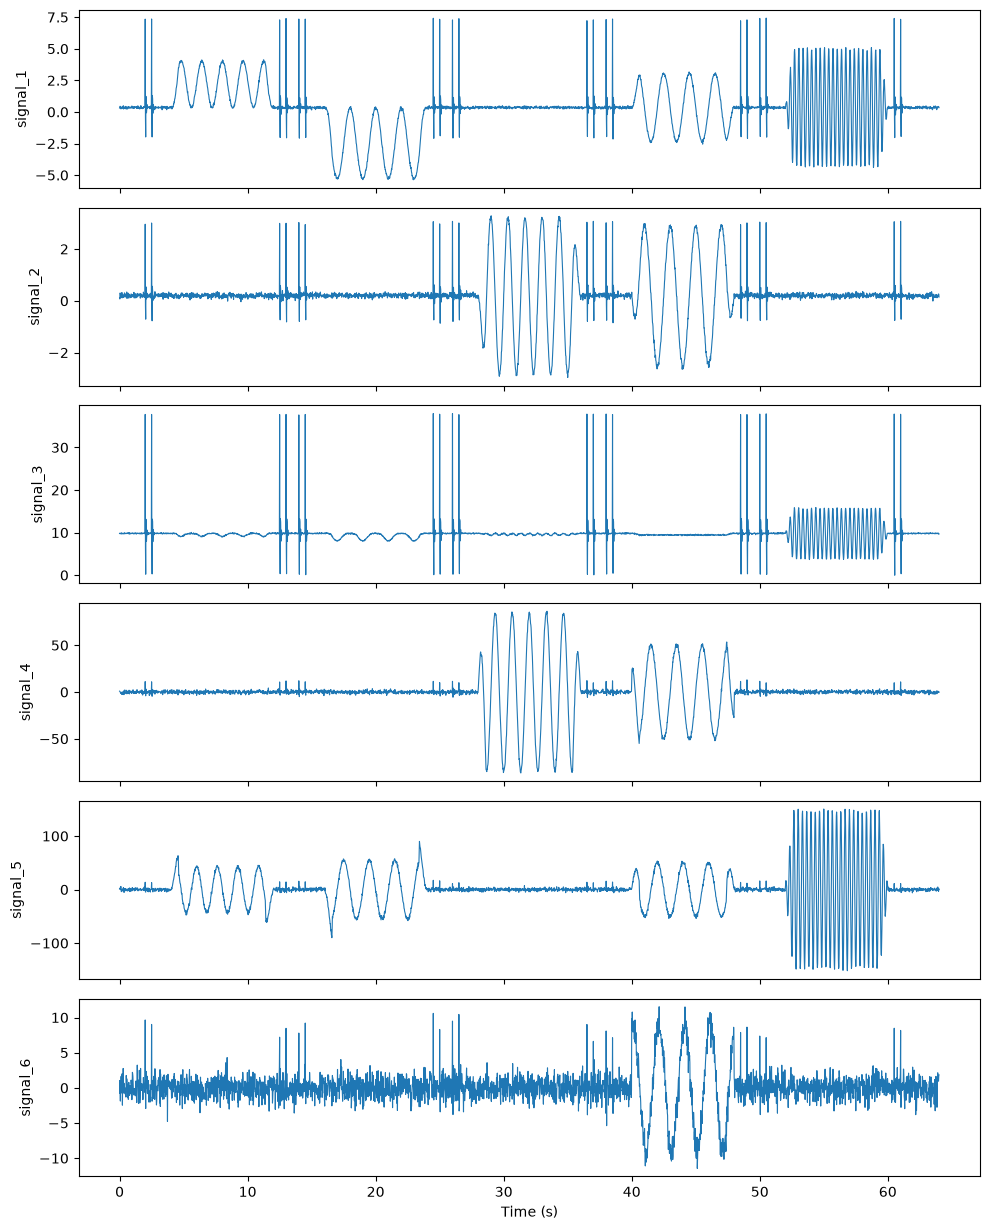

In [3]:
# ====================================================================
#  CELL 2: PLOT ALL SIGNALS
# ====================================================================
#
#  What it does: draws every signal against time, one panel per signal.
#  Nothing to change here.

signal_columns = [name for name in data.columns if name != "time_s"]

fig, axes = plt.subplots(len(signal_columns), 1, sharex=True, squeeze=False,
                         figsize=(10, 1.9 * len(signal_columns) + 1))
for ax, name in zip(axes.ravel(), signal_columns):
    ax.plot(data["time_s"], data[name], linewidth=0.8)
    ax.set_ylabel(name)
axes[-1, 0].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

## Cell 3: Pick one signal

Choose ONE signal and give it the correct axis label: the quantity and its unit, taken from your label table (Part A of the Session 3 worksheet).

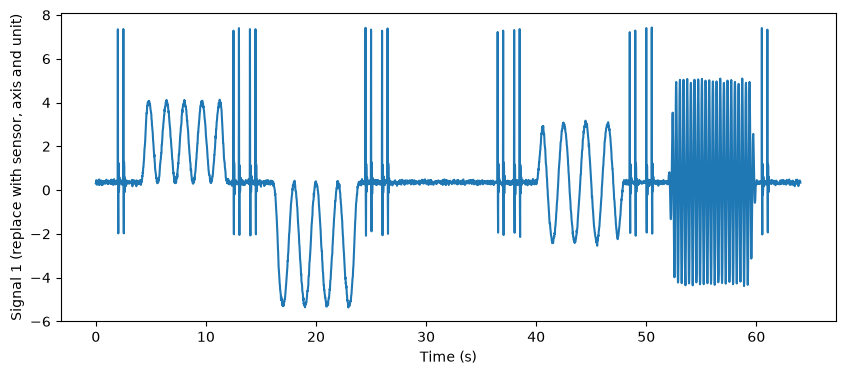

In [4]:
# ====================================================================
#  CELL 3: PICK ONE SIGNAL
# ====================================================================
#
#  What it does: draws a single column with a proper label on the vertical axis.
#
# +------------------------------------------------------------------+
# |  >>> YOU MAY CHANGE THIS <<<                                     |
# +------------------------------------------------------------------+
#
#  COLUMN_NAME: the EXACT name of the column (see the list printed by Cell 1),
#               in quotation marks.
#  Y_LABEL:     what you want to read on the vertical axis: sensor, axis and unit,
#               from your Part A table.
#               Example: "Accelerometer Z (m/s²)" or "Gyroscope Y (deg/s)"
#
COLUMN_NAME = "signal_1"
Y_LABEL = "Signal 1 (replace with sensor, axis and unit)"
#
# --------------------------------------------------------------------
#  Everything below this line: do not change.
# --------------------------------------------------------------------

plt.figure(figsize=(10, 4))
plt.plot(data["time_s"], data[COLUMN_NAME])
plt.xlabel("Time (s)")
plt.ylabel(Y_LABEL)
plt.show()

## Cell 4: Zoom in on one moment

Pick a time interval (one movement, or one peak) and give the plot a title that says what you are looking at. Use the tap markers you saw in Cell 2 to find where each movement starts and ends. Cell 4 uses the column and the label you chose in Cell 3.

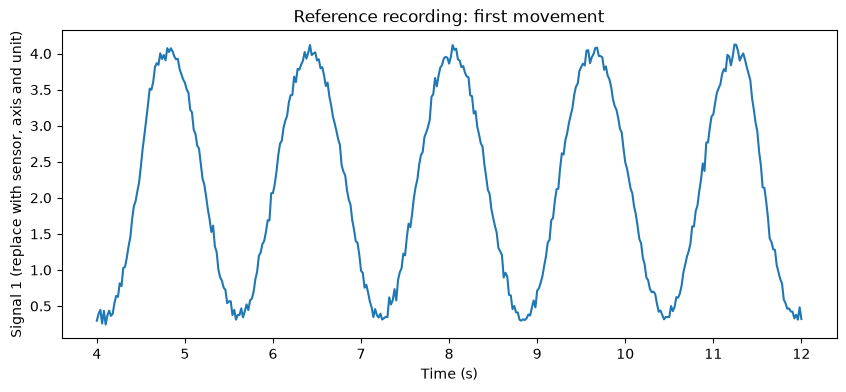

In [5]:
# ====================================================================
#  CELL 4: ZOOM TO A TIME WINDOW
# ====================================================================
#
#  What it does: shows only part of the signal chosen in Cell 3 and adds a title.
#
# +------------------------------------------------------------------+
# |  >>> YOU MAY CHANGE THIS <<<                                     |
# +------------------------------------------------------------------+
#
#  START_TIME: second where the zoom begins (a number)
#  END_TIME:   second where the zoom ends (must be LARGER than START_TIME)
#  TITLE:      title of the plot, in quotation marks, saying what you see
#              Example: "Foot lift, three repetitions"
#
START_TIME = 4
END_TIME = 12
TITLE = "Reference recording: first movement"
#
# --------------------------------------------------------------------
#  Everything below this line: do not change.
# --------------------------------------------------------------------

window = data[(data["time_s"] >= START_TIME) & (data["time_s"] <= END_TIME)]

if len(window) == 0:
    print(f"No data between {START_TIME} s and {END_TIME} s. "
          f"The recording runs from {data['time_s'].min()} s to {data['time_s'].max()} s.")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(window["time_s"], window[COLUMN_NAME])
ax.set_xlabel("Time (s)")
ax.set_ylabel(Y_LABEL)
ax.set_title(TITLE)
plt.show()

## Cell 5: Save your figure

Your figure is saved as a PNG image. Find it in the file browser on the left, right-click it and choose Download. Then put it in your group folder.

In [ ]:
# ====================================================================
#  CELL 5: SAVE THE FIGURE
# ====================================================================
#
#  What it does: saves the plot from Cell 4 as a PNG image, exactly as you see it there.
#
# +------------------------------------------------------------------+
# |  >>> YOU MAY CHANGE THIS <<<                                     |
# +------------------------------------------------------------------+
#
#  OUTPUT_NAME: the name of the image file. It must end in .png
#  Example: "group3_movement2.png"
#
OUTPUT_NAME = "figure.png"
#
# --------------------------------------------------------------------
#  Everything below this line: do not change.
# --------------------------------------------------------------------

if not OUTPUT_NAME.lower().endswith(".png"):
    OUTPUT_NAME = OUTPUT_NAME + ".png"

fig.savefig(OUTPUT_NAME, dpi=150, bbox_inches="tight")
print(f"Saved as {OUTPUT_NAME}")